# 8. Comparación estadística

Con 165 combinaciones hay más de 13 000 pares posibles; probarlos uno a uno con α = 0,05 produciría cientos de falsos positivos. Por eso la comparación sigue una secuencia jerárquica: **clasificación**, Friedman → Nemenyi y diagrama de diferencia crítica → DeLong dirigido con corrección por comparaciones múltiples → tamaño del efecto; **regresión**, Model Confidence Set → Giacomini-White y Clark-West → Diebold-Mariano con corrección HLN y *bootstrap* estacionario → tamaño del efecto.

## 8.1 Clasificación: prueba ómnibus de Friedman, Nemenyi y diagrama de diferencia crítica

Los bloques son los cinco pliegues del bucle externo y la métrica es el AUC-PR. Primero se prueban todas las combinaciones de clasificación y después los siete finalistas (el mejor de cada modelo). Como cinco bloques dan poca potencia, se agrega un análisis de sensibilidad con bloques mensuales: el AUC-PR de las predicciones fuera de muestra de cada finalista en cada mes de validación externa.

Comparación,Modelos (k),Bloques (N),χ²_F,g. l.,p (χ²),F de Iman-Davenport,p (F),Diferencia crítica de Nemenyi,Conclusión
Todas las combinaciones de clasificación,132,5,"199,883",131,"< 0,001","1,757","< 0,001","106,950",Se rechaza H0
Finalistas (bloques = pliegues externos),7,5,"2,486",6,"0,870","0,361","0,896","4,028",No se rechaza H0
Finalistas (bloques = meses de validación),7,8,"3,482",6,"0,746","0,548","0,769","3,185",No se rechaza H0


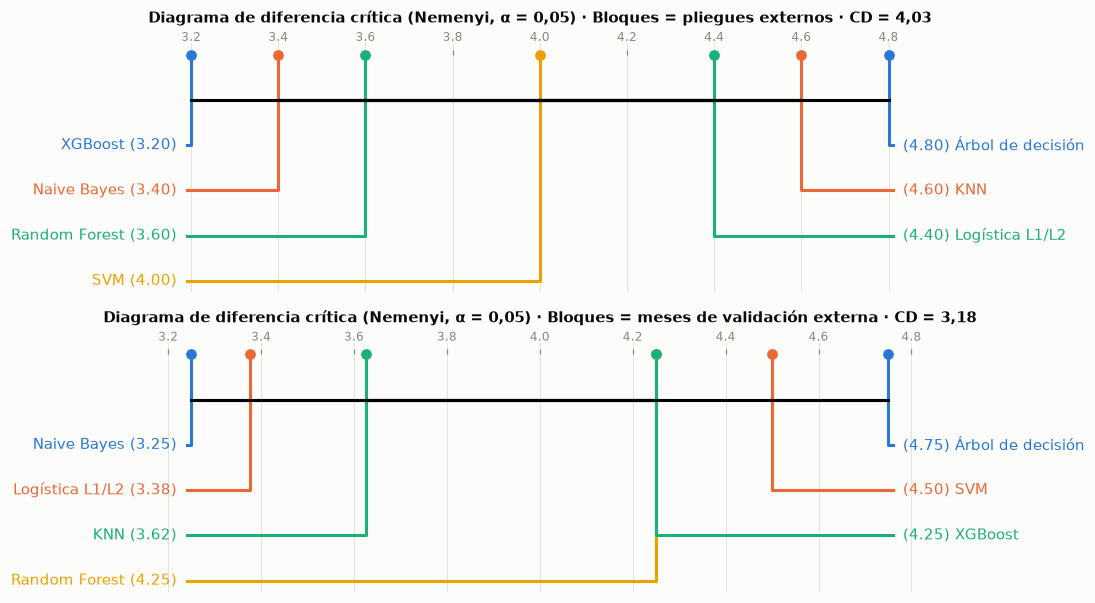

**Interpretación.** Sobre todas las combinaciones, Friedman da χ² = 199,9 con 131 g. l. (p < 0,001); entre los siete finalistas con bloques por pliegue, χ² = 2,49 (p = 0,870) y diferencia crítica de 4,03 rangos; con 8 bloques mensuales, χ² = 3,48 (p = 0,746) y diferencia crítica de 3,18. El mejor rango promedio entre finalistas es el de XGBoost (3,20) por pliegues y el de Naive Bayes (3,25) por meses.

Esto significa que hay evidencia de que al menos una de las 132 combinaciones difiere de las demás (sobre todo por las peores, con balanceos o espacios que fallan en algunos pliegues), pero entre los siete finalistas no hay evidencia de diferencias, ni con bloques por pliegue ni con bloques mensuales: todos quedan dentro de la diferencia crítica de Nemenyi y son estadísticamente equivalentes. Con pocos bloques la diferencia crítica es amplia, así que la equivalencia también refleja la poca potencia de la prueba, no solo la igualdad real de los modelos.

Por tanto, corresponde comparar de forma dirigida solo los finalistas que encabezan el ranking, con DeLong sobre la prueba y corrección por comparaciones múltiples (sección 8.2), y no declarar un ganador a partir de diferencias que el diagrama muestra como no significativas.

In [72]:
mat_all = clf_pl.pivot_table(index="pliegue", columns=["modelo", "balanceo", "optimizador"], values="auc_pr")
fr_all = st.friedman(mat_all)
fin_ext = evm.elegir_finalistas(maestra, "clf")
claves_fin = [(r_.modelo, r_.balanceo, r_.optimizador) for r_ in fin_ext.itertuples()]
mat_fin = mat_all[claves_fin]
mat_fin.columns = [NM[c[0]] for c in claves_fin]
fr_fin = st.friedman(mat_fin)

# Sensibilidad: bloques = meses de validación externa (predicciones fuera de muestra)
o_c = oof[oof["tarea"] == "clf"].copy()
o_c["periodo"] = tiempo.loc[o_c["indice"], "periodo"].to_numpy()
filas = {}
for (m_, b_, op_), nombre in zip(claves_fin, mat_fin.columns):
    d_ = o_c[(o_c["modelo"] == m_) & (o_c["balanceo"] == b_) & (o_c["optimizador"] == op_)]
    filas[nombre] = d_.groupby("periodo").apply(
        lambda g: average_precision_score(g["y"], g["puntaje"]) if 0 < g["y"].sum() < len(g) and len(g) >= 100 else np.nan,
        include_groups=False)
mat_mes = pd.DataFrame(filas).dropna()
fr_mes = st.friedman(mat_mes)

omni = pd.DataFrame([
    ("Todas las combinaciones de clasificación", fr_all), ("Finalistas (bloques = pliegues externos)", fr_fin),
    ("Finalistas (bloques = meses de validación)", fr_mes)], columns=["Comparación", "r"])
omni = pd.DataFrame({"Comparación": omni["Comparación"], "Modelos (k)": [r_["k_modelos"] for r_ in omni["r"]],
                     "Bloques (N)": [r_["n_bloques"] for r_ in omni["r"]], "χ²_F": [r_["chi2"] for r_ in omni["r"]],
                     "g. l.": [r_["gl"] for r_ in omni["r"]], "p (χ²)": [pval(r_["p"]) for r_ in omni["r"]],
                     "F de Iman-Davenport": [r_["F_ID"] for r_ in omni["r"]],
                     "p (F)": [pval(r_["p_F_ID"]) for r_ in omni["r"]],
                     "Diferencia crítica de Nemenyi": [st.diferencia_critica(r_["k_modelos"], r_["n_bloques"])
                                                       for r_ in omni["r"]],
                     "Conclusión": ["Se rechaza H0" if r_["p"] < 0.05 else "No se rechaza H0" for r_ in omni["r"]]})
tabla(omni, dec=3, indice=False)

fig, axs = plt.subplots(2, 1, figsize=(10, 5.6))
for ax, M, fr, titulo in ((axs[0], mat_fin, fr_fin, "Bloques = pliegues externos"),
                          (axs[1], mat_mes, fr_mes, "Bloques = meses de validación externa")):
    nem = sp.posthoc_nemenyi_friedman(M.to_numpy())
    nem.index = nem.columns = M.columns
    plt.sca(ax)
    sp.critical_difference_diagram(fr["rangos"], nem, ax=ax, label_fmt_left="{label} ({rank:.2f})  ",
                                   label_fmt_right="  ({rank:.2f}) {label}")
    ax.set_title(f"Diagrama de diferencia crítica (Nemenyi, α = 0,05) · {titulo} · CD = "
                 f"{num(st.diferencia_critica(fr['k_modelos'], fr['n_bloques']), 2)}", fontsize=9.5)
plt.tight_layout()
plt.show()

interpretar(
    f"Sobre todas las combinaciones, Friedman da χ² = {num(fr_all['chi2'], 1)} con {fr_all['gl']} g. l. "
    f"({p_txt(fr_all['p'])}); entre los siete finalistas con bloques por pliegue, χ² = {num(fr_fin['chi2'], 2)} "
    f"({p_txt(fr_fin['p'])}) y diferencia crítica de {num(st.diferencia_critica(7, fr_fin['n_bloques']), 2)} rangos; con "
    f"{fr_mes['n_bloques']} bloques mensuales, χ² = {num(fr_mes['chi2'], 2)} ({p_txt(fr_mes['p'])}) y diferencia crítica "
    f"de {num(st.diferencia_critica(7, fr_mes['n_bloques']), 2)}. El mejor rango promedio entre finalistas es el de "
    f"{fr_fin['rangos'].index[0]} ({num(fr_fin['rangos'].iloc[0], 2)}) por pliegues y el de {fr_mes['rangos'].index[0]} "
    f"({num(fr_mes['rangos'].iloc[0], 2)}) por meses.",
    conectar("Esto significa que", ("Hay evidencia de que al menos una de las 132 combinaciones difiere de las demás "
             "(sobre todo por las peores, con balanceos o espacios que fallan en algunos pliegues)"
             if fr_all["p"] < 0.05 else "No hay evidencia de que alguna combinación difiera de las demás")
             + (", pero entre los siete finalistas no hay evidencia de diferencias, ni con bloques por pliegue ni con "
                "bloques mensuales: todos quedan dentro de la diferencia crítica de Nemenyi y son estadísticamente "
                "equivalentes. "
                if fr_fin["p"] >= 0.05 and fr_mes["p"] >= 0.05 else
                "; entre los finalistas, el diagrama muestra qué pares se separan más que la diferencia crítica. ")
             + "Con pocos bloques la diferencia crítica es amplia, así que la equivalencia también refleja la poca "
             "potencia de la prueba, no solo la igualdad real de los modelos."),
    conectar("Por tanto, corresponde", "Comparar de forma dirigida solo los finalistas que encabezan el ranking, con "
             "DeLong sobre la prueba y corrección por comparaciones múltiples (sección 8.2), y no declarar un ganador a "
             "partir de diferencias que el diagrama muestra como no significativas."))

exportar("friedman_omnibus", omni)
exportar("rangos_cd", pd.concat([fr_fin["rangos"].rename("rango").rename_axis("modelo").reset_index().assign(bloques="pliegues",
          cd=st.diferencia_critica(fr_fin["k_modelos"], fr_fin["n_bloques"])),
          fr_mes["rangos"].rename("rango").rename_axis("modelo").reset_index().assign(bloques="meses",
          cd=st.diferencia_critica(fr_mes["k_modelos"], fr_mes["n_bloques"]))]))


## 8.2 Clasificación: comparaciones dirigidas con DeLong, *bootstrap* y tamaño del efecto

Se comparan en la prueba los tres finalistas con mayor AUC entre sí y el mejor contra el modelo base del Entregable 2. DeLong prueba la igualdad de dos AUC correlacionadas (mismas observaciones); los valores p se ajustan con Holm-Bonferroni y con Benjamini-Hochberg, y la diferencia de AUC lleva un intervalo *bootstrap* BCa pareado. El delta de Cliff sobre el AUC-PR de los cinco pliegues externos mide el tamaño del efecto en la validación anidada.

In [73]:
top3 = res_te[~res_te["clave"].str.endswith("e2")].sort_values("AUC", ascending=False)["clave"].iloc[:3].tolist()
pares_d = [(top3[0], top3[1]), (top3[0], top3[2]), (top3[1], top3[2]), (top3[0], "clf_referencia_e2")]
nombre_k = lambda k: "Referencia E2" if k.endswith("e2") else NM[fin_clf[k]["modelo"]]
ap_pl = {NM[c[0]]: mat_fin[NM[c[0]]].to_numpy() for c in claves_fin}
filas = []
for a_, b_ in pares_d:
    sa, sb = fin_clf[a_]["puntaje_te"], fin_clf[b_]["puntaje_te"]
    dl = st.delong(yte, sa, sb)
    ic = st.ic_bootstrap(lambda y_, s1, s2: roc_auc_score(y_, s1) - roc_auc_score(y_, s2), yte, sa, sb, n_rep=1000)
    cl = st.delta_cliff(ap_pl[nombre_k(a_)], ap_pl[nombre_k(b_)]) if not b_.endswith("e2") else np.nan
    filas.append({"Modelo A": nombre_k(a_), "Modelo B": nombre_k(b_), "AUC A": dl["auc_a"], "AUC B": dl["auc_b"],
                  "Diferencia de AUC": dl["diferencia"], "IC 95 % BCa": f"[{num(ic[0], 4)}; {num(ic[1], 4)}]",
                  "z": dl["z"], "p crudo": dl["p"], "delta de Cliff (AUC-PR externo)": cl})
dl_t = pd.DataFrame(filas)
dl_t["p Holm"] = st.ajustar_p(dl_t["p crudo"], "holm")
dl_t["p BH"] = st.ajustar_p(dl_t["p crudo"], "fdr_bh")
dl_t["Magnitud (Cliff)"] = dl_t["delta de Cliff (AUC-PR externo)"].map(lambda d: st.magnitud_cliff(d) if np.isfinite(d) else "—")
tabla(dl_t.assign(**{c: dl_t[c].map(pval) for c in ("p crudo", "p Holm", "p BH")}), dec=4, indice=False)

r0 = dl_t.iloc[0]
rE = dl_t.iloc[-1]
interpretar(
    f"Entre {r0['Modelo A']} y {r0['Modelo B']}, la diferencia de AUC en prueba es de {num(r0['Diferencia de AUC'], 4)} "
    f"{r0['IC 95 % BCa']} (p de Holm {pval(r0['p Holm'])}); frente a la referencia del Entregable 2, {rE['Modelo A']} "
    f"difiere en {num(rE['Diferencia de AUC'], 4)} {rE['IC 95 % BCa']} (p de Holm {pval(rE['p Holm'])}). "
    f"{int((dl_t['p Holm'] < 0.05).sum())} de las {len(dl_t)} comparaciones son significativas tras el ajuste.",
    (("Hay que tener en cuenta que, aun con más de 8 000 observaciones de prueba, ninguna diferencia de AUC es "
      "significativa tras el ajuste: los mejores finalistas y el modelo base del Entregable 2 son estadísticamente "
      "equivalentes en su capacidad de ordenar a los clientes, y las diferencias de pocas milésimas no cambian la "
      "lista de clientes a llamar. El intervalo de la diferencia y el delta de Cliff confirman que el efecto es pequeño."
      if (dl_t["p Holm"] >= 0.05).all() else
      "Hay que tener en cuenta que, con más de 8 000 observaciones de prueba, DeLong detecta diferencias de AUC muy "
      "pequeñas; por eso el intervalo de la diferencia y el delta de Cliff importan tanto como el valor p.")),
    conectar("Con base en esto, se propone", "Elegir entre los modelos estadísticamente equivalentes por criterios "
             "secundarios: costo de entrenamiento, calibración e interpretabilidad. Con esos criterios, la logística "
             "regularizada del Entregable 2 sigue siendo una opción muy competitiva, porque es la más barata y la más "
             "fácil de explicar, y su recalibración mensual solo desplaza el intercepto sin cambiar el orden."))

exportar("delong", dl_t)


Modelo A,Modelo B,AUC A,AUC B,Diferencia de AUC,IC 95 % BCa,z,p crudo,delta de Cliff (AUC-PR externo),p Holm,p BH,Magnitud (Cliff)
Random Forest,Naive Bayes,"0,7202","0,7143","0,0059","[-0,0014; 0,0145]","1,4204","0,156","-0,0400","0,467","0,230",despreciable
Random Forest,SVM,"0,7202","0,7135","0,0066","[-0,0026; 0,0161]","1,3649","0,172","-0,0400","0,467","0,230",despreciable
Naive Bayes,SVM,"0,7143","0,7135","0,0007","[-0,0106; 0,0120]","0,1266","0,899","0,0400","0,899","0,899",despreciable
Random Forest,Referencia E2,"0,7202","0,7095","0,0106","[0,0001; 0,0211]","1,9846","0,047",—,"0,189","0,189",—


**Interpretación.** Entre Random Forest y Naive Bayes, la diferencia de AUC en prueba es de 0,0059 [-0,0014; 0,0145] (p de Holm 0,467); frente a la referencia del Entregable 2, Random Forest difiere en 0,0106 [0,0001; 0,0211] (p de Holm 0,189). 0 de las 4 comparaciones son significativas tras el ajuste.

Hay que tener en cuenta que, aun con más de 8 000 observaciones de prueba, ninguna diferencia de AUC es significativa tras el ajuste: los mejores finalistas y el modelo base del Entregable 2 son estadísticamente equivalentes en su capacidad de ordenar a los clientes, y las diferencias de pocas milésimas no cambian la lista de clientes a llamar. El intervalo de la diferencia y el delta de Cliff confirman que el efecto es pequeño.

Con base en esto, se propone elegir entre los modelos estadísticamente equivalentes por criterios secundarios: costo de entrenamiento, calibración e interpretabilidad. Con esos criterios, la logística regularizada del Entregable 2 sigue siendo una opción muy competitiva, porque es la más barata y la más fácil de explicar, y su recalibración mensual solo desplaza el intercepto sin cambiar el orden.

## 8.3 Regresión: Model Confidence Set, Giacomini-White, Clark-West y Diebold-Mariano

El **Model Confidence Set** (Hansen, Lunde y Nason, 2011) parte de las 33 combinaciones de regresión más la media histórica y elimina de forma iterativa, con *bootstrap* estacionario, los modelos significativamente peores, hasta dejar un conjunto de modelos indistinguibles del mejor con confianza del 90 %. Las pérdidas son los errores cuadráticos de las predicciones fuera de muestra del bucle externo, en orden temporal. Sobre los finalistas se aplican, en la prueba:

- **Giacomini-White** (condicional, instrumentos 1 y la diferencia de pérdida rezagada) entre el mejor y el segundo, que no están anidados.
- **Clark-West** entre la media histórica y el mejor modelo: la media es un caso particular de cualquier modelo con intercepto (modelos anidados), donde Diebold-Mariano está sesgado.
- **Diebold-Mariano con corrección HLN** entre el mejor y el segundo, con el intervalo de la diferencia media de pérdida por *bootstrap* estacionario (Politis y Romano, 1994) y la d de Cohen.
- **SPA de Hansen** (2005): ¿algún finalista supera a la media histórica, controlando el *data snooping*?

In [74]:
o_r = oof[oof["tarea"] == "reg"].copy()
o_r["etiqueta"] = o_r["modelo"].map(NM) + " · " + o_r["optimizador"].map(NO)
L = (o_r.assign(e2=(o_r["y"] - o_r["pred"]) ** 2)
     .pivot_table(index="indice", columns="etiqueta", values="e2").sort_index())
bench = pd.Series(np.nan, index=X_tr.index)
for i_e, i_v in cv_externa(GAP).split(X_tr):
    bench.iloc[i_v] = rtr[i_e].mean()
L["Media histórica (referencia)"] = ((part.r_tr - bench) ** 2).loc[L.index]
mcs = st.model_confidence_set(L, alfa=0.10, n_rep=1000)
tabla(mcs.rename(columns={"perdida_media": "Pérdida media (MSE)", "rango_promedio": "Rango promedio de pérdida",
                          "p_MCS": "p MCS", "en_conjunto": "¿En el conjunto de confianza?"})
      .assign(**{"¿En el conjunto de confianza?": lambda d: d["¿En el conjunto de confianza?"].map({True: "Sí", False: "No"})}),
      dec=4)

orden_te = res_reg[res_reg["clave"] != "media"].sort_values("RMSE (log)")["clave"].tolist()
k1, k2 = orden_te[0], orden_te[1]
p1, p2 = fin_reg[k1]["pred_te"], fin_reg[k2]["pred_te"]
pm = np.full_like(rte, media_tr)
e1, e2, em = rte - p1, rte - p2, rte - pm
gw = st.giacomini_white(e2 ** 2, e1 ** 2)
cw = st.clark_west(rte, pm, p1)
dm = st.diebold_mariano(e2, e1)
dm_b = st.diebold_mariano(em, e1)
bs = st.ic_bootstrap_estacionario(e2 ** 2 - e1 ** 2)
spa_p = st.spa(em ** 2, pd.DataFrame({k: (rte - fin_reg[k]["pred_te"]) ** 2 for k in orden_te}))
dirigidas = pd.DataFrame([
    ("Giacomini-White condicional", f"{NM[fin_reg[k2]['modelo']]} vs {NM[fin_reg[k1]['modelo']]}", gw["GW"], gw["p"],
     gw["dif_media"]),
    ("Clark-West (anidados)", f"Media histórica ⊂ {NM[fin_reg[k1]['modelo']]}", cw["CW"], cw["p"], np.mean(em ** 2 - e1 ** 2)),
    ("Diebold-Mariano (HLN)", f"{NM[fin_reg[k2]['modelo']]} vs {NM[fin_reg[k1]['modelo']]}", dm["DM_HLN"], dm["p"],
     dm["dif_perdida"]),
    ("Diebold-Mariano (HLN)", f"Media histórica vs {NM[fin_reg[k1]['modelo']]}", dm_b["DM_HLN"], dm_b["p"],
     dm_b["dif_perdida"]),
], columns=["Prueba", "Comparación (pérdida 1 − pérdida 2)", "Estadístico", "p crudo", "Diferencia media de pérdida"])
dirigidas["p Holm"] = st.ajustar_p(dirigidas["p crudo"], "holm")
dirigidas["d de Cohen"] = [st.d_cohen(e2 ** 2 - e1 ** 2), st.d_cohen(em ** 2 - e1 ** 2), st.d_cohen(e2 ** 2 - e1 ** 2),
                           st.d_cohen(em ** 2 - e1 ** 2)]
tabla(dirigidas.assign(**{c: dirigidas[c].map(pval) for c in ("p crudo", "p Holm")}), dec=4, indice=False)
print(f"Bootstrap estacionario de la diferencia media de pérdida ({NM[fin_reg[k2]['modelo']]} − "
      f"{NM[fin_reg[k1]['modelo']]}): {num(bs['media'], 5)} [IC 95 %: {num(bs['ic_inf'], 5)}; {num(bs['ic_sup'], 5)}], "
      f"bloque medio {num(bs['bloque'], 1)}")
print(f"SPA de Hansen (referencia = media histórica): p = {num(spa_p['consistent'], 3)} (consistente), "
      f"{num(spa_p['lower'], 3)} (inferior), {num(spa_p['upper'], 3)} (superior)")

en_mcs = mcs[mcs["en_conjunto"]]
interpretar(
    f"El Model Confidence Set al 90 % conserva {len(en_mcs)} de los {len(mcs)} modelos"
    + (", incluida la media histórica" if "Media histórica (referencia)" in en_mcs.index else ", y excluye la media histórica")
    + f"; la menor pérdida media es la de {mcs.index[0]} ({num(mcs['perdida_media'].iloc[0], 4)}). En prueba, "
    f"Clark-West contra la media da {p_txt(cw['p'])}, Giacomini-White entre los dos mejores finalistas "
    f"{p_txt(gw['p'])}, Diebold-Mariano entre ellos {p_txt(dm['p'])} (p de Holm {pval(dirigidas['p Holm'].iloc[2])}, "
    f"d de Cohen {num(dirigidas['d de Cohen'].iloc[2], 3)}) y la SPA {p_txt(spa_p['consistent'])}.",
    conectar("En síntesis,", ("Hay modelos que superan de forma estadísticamente significativa a la media histórica, "
             "pero el tamaño del efecto es pequeño: la mejora en el error cuadrático es una fracción mínima de la "
             "variabilidad de la duración."
             if (cw["p"] < 0.05 or spa_p["consistent"] < 0.05) else
             "No hay evidencia de que algún modelo pronostique la duración mejor que la media histórica: el MCS no "
             "los distingue y las pruebas dirigidas no rechazan la igualdad de capacidad predictiva.")
             + (" Entre los dos mejores finalistas, Giacomini-White indica que su ventaja relativa depende del "
                "estado reciente (la diferencia de pérdida rezagada predice la siguiente)." if gw["p"] < 0.05 else
                " Entre los dos mejores finalistas, Giacomini-White no encuentra que la ventaja relativa dependa del "
                "estado reciente.")),
    conectar("Así las cosas, se decide", ("Concluir que los modelos sí superan a la media histórica de forma "
             "significativa, pero con una ganancia demasiado pequeña (R² menor que 0,1) para planificar la carga de los "
             "asesores llamada a llamada; como estimación del nivel medio, la media histórica es casi igual de útil y "
             "mucho más simple." if "Media histórica (referencia)" not in en_mcs.index else
             "Concluir que la rama de regresión no aporta un pronóstico útil de la duración con información previa a "
             "la llamada: la media histórica queda en el conjunto de confianza junto a los modelos optimizados.")))

exportar("mcs", mcs.reset_index(names="modelo"))
exportar("pruebas_regresion", dirigidas)
exportar("spa_bootstrap", {"spa": spa_p, "bootstrap": bs})


,Pérdida media (MSE),Rango promedio de pérdida,p MCS,¿En el conjunto de confianza?
etiqueta,,,,
XGBoost · Bayesiana (Optuna TPE),"0,8217","16,9603","1,0000",Sí
XGBoost · Random Search,"0,8220","17,0731","0,8770",Sí
XGBoost · GOAT iterativo,"0,8229","17,0399","0,5440",Sí
XGBoost · Grid Search,"0,8232","16,9519","0,3480",Sí
XGBoost · Genético (DEAP),"0,8253","16,9142","0,3470",Sí
Random Forest · Random Search,"0,8253","17,2523","0,3470",Sí
Random Forest · Grid Search,"0,8257","17,1734","0,3010",Sí
Random Forest · Genético (DEAP),"0,8258","17,2634","0,3080",Sí
Random Forest · Bayesiana (Optuna TPE),"0,8280","17,1697","0,1090",Sí


Prueba,Comparación (pérdida 1 − pérdida 2),Estadístico,p crudo,Diferencia media de pérdida,p Holm,d de Cohen
Giacomini-White condicional,Árbol de decisión vs Random Forest,"57,7314","< 0,001","0,0085","< 0,001","0,0244"
Clark-West (anidados),Media histórica ⊂ Random Forest,"13,5949","< 0,001","0,0827","< 0,001","0,1565"
Diebold-Mariano (HLN),Árbol de decisión vs Random Forest,"2,2118","0,027","0,0085","0,027","0,0244"
Diebold-Mariano (HLN),Media histórica vs Random Forest,"14,2010","< 0,001","0,0827","< 0,001","0,1565"


Bootstrap estacionario de la diferencia media de pérdida (Árbol de decisión − Random Forest): 0,00846 [IC 95 %: -0,00723; 0,02564], bloque medio 70,1
SPA de Hansen (referencia = media histórica): p = 0,003 (consistente), 0,003 (inferior), 0,003 (superior)


**Interpretación.** El Model Confidence Set al 90 % conserva 9 de los 34 modelos, y excluye la media histórica; la menor pérdida media es la de XGBoost · Bayesiana (Optuna TPE) (0,8217). En prueba, Clark-West contra la media da p < 0,001, Giacomini-White entre los dos mejores finalistas p < 0,001, Diebold-Mariano entre ellos p = 0,027 (p de Holm 0,027, d de Cohen 0,024) y la SPA p = 0,003.

En síntesis, hay modelos que superan de forma estadísticamente significativa a la media histórica, pero el tamaño del efecto es pequeño: la mejora en el error cuadrático es una fracción mínima de la variabilidad de la duración. Entre los dos mejores finalistas, Giacomini-White indica que su ventaja relativa depende del estado reciente (la diferencia de pérdida rezagada predice la siguiente).

Así las cosas, se decide concluir que los modelos sí superan a la media histórica de forma significativa, pero con una ganancia demasiado pequeña (R² menor que 0,1) para planificar la carga de los asesores llamada a llamada; como estimación del nivel medio, la media histórica es casi igual de útil y mucho más simple.

## 8.4 Intervalos de confianza al 95 % de las métricas principales

Intervalos *bootstrap* BCa con 1 000 réplicas sobre el conjunto de prueba (AUC y AUC-PR para clasificación, RMSE en escala log para regresión).

In [75]:
filas = [{"Modelo": r_["Modelo"], "Métrica": "AUC", "Valor": r_["AUC"], "IC 95 % inferior": r_["ic_auc"][0],
          "IC 95 % superior": r_["ic_auc"][1]} for _, r_ in res_te.iterrows()]
filas += [{"Modelo": r_["Modelo"], "Métrica": "AUC-PR", "Valor": r_["AUC-PR"], "IC 95 % inferior": r_["ic_ap"][0],
           "IC 95 % superior": r_["ic_ap"][1]} for _, r_ in res_te.iterrows()]
for k in orden_reg:
    ic = st.ic_bootstrap(root_mean_squared_error, rte, fin_reg[k]["pred_te"], n_rep=1000)
    filas.append({"Modelo": NM[fin_reg[k]["modelo"]], "Métrica": "RMSE (log)",
                  "Valor": root_mean_squared_error(rte, fin_reg[k]["pred_te"]), "IC 95 % inferior": ic[0],
                  "IC 95 % superior": ic[1]})
ic_tab = pd.DataFrame(filas)
tabla(ic_tab, dec=4, indice=False)
anchos = ic_tab.assign(ancho=ic_tab["IC 95 % superior"] - ic_tab["IC 95 % inferior"]).groupby("Métrica")["ancho"].mean()
print("Ancho medio del intervalo: " + "; ".join(f"{k} {num(v, 4)}" for k, v in anchos.items()))

exportar("intervalos", ic_tab)


Modelo,Métrica,Valor,IC 95 % inferior,IC 95 % superior
KNN,AUC,"0,6880","0,6754","0,7010"
Naive Bayes,AUC,"0,7143","0,7019","0,7272"
Logística L1/L2,AUC,"0,6815","0,6674","0,6945"
Árbol de decisión,AUC,"0,5669","0,5538","0,5797"
Random Forest,AUC,"0,7202","0,7084","0,7319"
XGBoost,AUC,"0,5820","0,5677","0,5951"
SVM,AUC,"0,7135","0,7002","0,7252"
"Referencia E2 (logística C = 0,01)",AUC,"0,7095","0,6960","0,7213"
KNN,AUC-PR,"0,4998","0,4781","0,5184"
Naive Bayes,AUC-PR,"0,5343","0,5147","0,5520"


Ancho medio del intervalo: AUC 0,0256; AUC-PR 0,0395; RMSE (log) 0,0376
